# Modul

In [ ]:
import tensorflow as tf
import matplotlib.pyplot as plt
import random
import numpy as np

from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Conv2D, MaxPooling2D, Dropout, Flatten

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
data_path = "/content/drive/My Drive/Kuliah/Penambangan Data/CNN"

IMAGE_SIZE = 224 #model input size
BATCH_SIZE = 64

datagen = tf.keras.preprocessing.image.ImageDataGenerator(
    rescale = 1./255,
    validation_split=0.2)

train_generator = datagen.flow_from_directory(
    data_path,
    target_size=(IMAGE_SIZE, IMAGE_SIZE),
    batch_size = BATCH_SIZE,
    subset='training')

val_generator = datagen.flow_from_directory(
    data_path,
    target_size=(IMAGE_SIZE, IMAGE_SIZE),
    batch_size = BATCH_SIZE,
    subset='validation')

Found 80 images belonging to 2 classes.
Found 20 images belonging to 2 classes.


(64, 224, 224, 3)


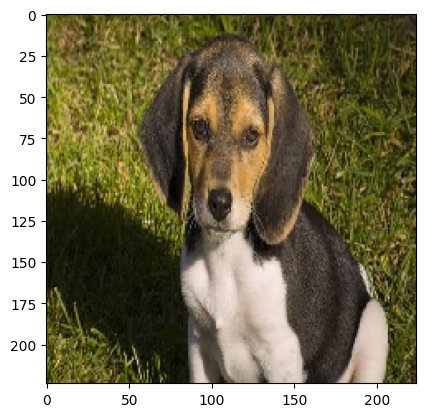

(16, 224, 224, 3)


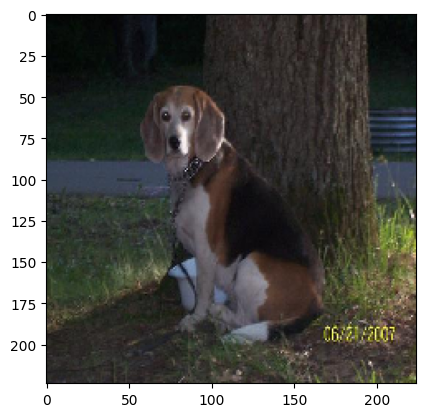

(64, 224, 224, 3)


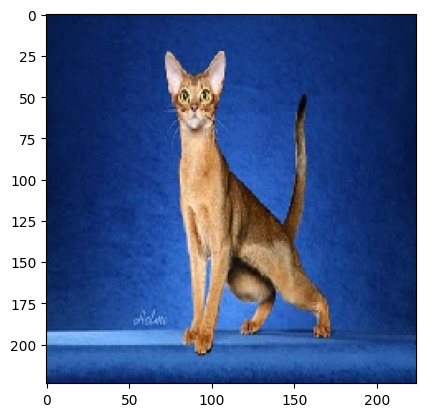

(16, 224, 224, 3)


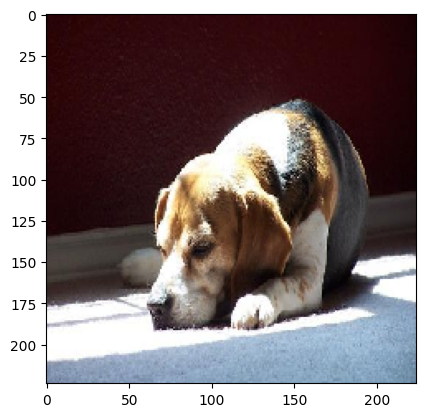

(64, 224, 224, 3)


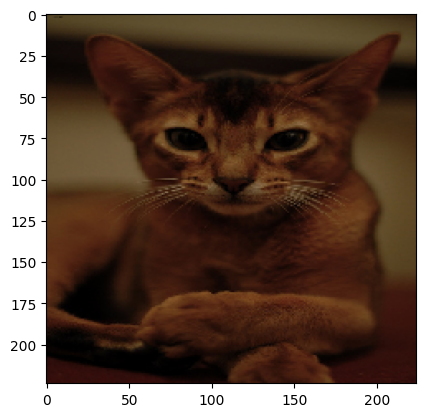

In [ ]:
for _ in range(5):
    img, label = next(train_generator)
    print(img.shape)
    plt.imshow(img[0])
    plt.show()

In [ ]:
for image_batch, label_batch in train_generator:
    break

print(f"Image batch shape: {image_batch.shape}")
print(f"Label batch shape: {label_batch.shape}")

IMG_SHAPE = (IMAGE_SIZE, IMAGE_SIZE, 3)

num_classes = 2

Image batch shape: (16, 224, 224, 3)
Label batch shape: (16, 2)


In [ ]:
model = Sequential()

#---------------------------------------
# Conv Block 1: 32 Filters, MaxPool.
#---------------------------------------
model.add(Conv2D(filters=32, kernel_size=3, padding='same', activation='relu', input_shape=IMG_SHAPE))
model.add(Conv2D(filters=32, kernel_size=3, padding='same', activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Dropout(0.1))
#---------------------------------------
# Conv Block 2: 64 Filters, MaxPool.
#---------------------------------------
model.add(Conv2D(filters=64, kernel_size=3, padding='same', activation='relu'))
model.add(Conv2D(filters=64, kernel_size=3, padding='same', activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))

# Flatten the convolutional features.
#---------------------------------------
model.add(Flatten())
model.add(Dense(512, activation='relu'))
model.add(Dense(num_classes, activation='softmax'))

model.compile(optimizer='rmsprop',
              loss='categorical_crossentropy',
              metrics=['accuracy'],
              )

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_32 (Conv2D)              │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_33 (Conv2D)              │ (None, 224, 224, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_16 (MaxPooling2D) │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_34 (Conv2D)              │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_35 (Conv2D)              │ (None, 112, 112, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_17 (MaxPooling2D) │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_8 (Flatten)             │ (None, 200704)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 512)            │   102,760,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 2)              │         1,026 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 102,827,554 (392.26 MB)

 Trainable params: 102,827,554 (392.26 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
epochs = 20
history = model.fit(train_generator,
                    epochs=epochs,
                    validation_data=val_generator)
loss, acc = model.evaluate(val_generator, verbose=1)

Epoch 1/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 8s 4s/step - accuracy: 0.4750 - loss: 6.3317 - val_accuracy: 0.5000 - val_loss: 6.1024
Epoch 2/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 403ms/step - accuracy: 0.5250 - loss: 2.0857 - val_accuracy: 0.5000 - val_loss: 0.7029
Epoch 3/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 409ms/step - accuracy: 0.5250 - loss: 0.6860 - val_accuracy: 0.5000 - val_loss: 0.6790
Epoch 4/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 165ms/step - accuracy: 0.5875 - loss: 0.6368 - val_accuracy: 0.5000 - val_loss: 1.1048
Epoch 5/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 392ms/step - accuracy: 0.5250 - loss: 2.7687 - val_accuracy: 0.5000 - val_loss: 1.2422
Epoch 6/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 163ms/step - accuracy: 0.4500 - loss: 1.7506 - val_accuracy: 0.5000 - val_loss: 0.6957
Epoch 7/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 410ms/step - accuracy: 0.7500 - loss: 0.6832 - val_accuracy: 0.7000 - val_loss: 0.6872
Epoch 8/20
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 150ms/step - accuracy: 0.8250 - loss: 0.6700 - val_accuracy: 0.5000 - val_loss: 0.

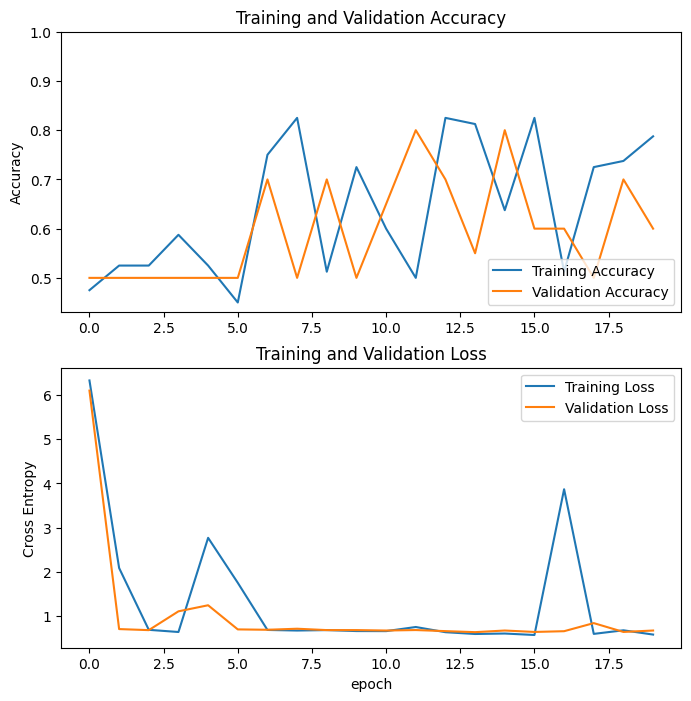

In [ ]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

plt.figure(figsize=(8, 8))
plt.subplot(2, 1, 1)
plt.plot(acc, label='Training Accuracy')
plt.plot(val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.ylabel('Accuracy')
plt.ylim([min(plt.ylim()),1])
plt.title('Training and Validation Accuracy')

plt.subplot(2, 1, 2)
plt.plot(loss, label='Training Loss')
plt.plot(val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.ylabel('Cross Entropy')
plt.title('Training and Validation Loss')
plt.xlabel('epoch')
plt.show()

# Tugas

In [ ]:
import tensorflow as tf
import matplotlib.pyplot as plt
import random
import numpy as np

from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Conv2D, MaxPooling2D, Dropout, Flatten
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
base_path = "/content/drive/My Drive/Kuliah/Penambangan Data/Intel Image Classification"
train_path = base_path + "/seg_train/seg_train"
val_path = base_path + "/seg_test/seg_test"

IMAGE_SIZE = 150
BATCH_SIZE = 64

train_datagen = tf.keras.preprocessing.image.ImageDataGenerator(rescale = 1./255, rotation_range=20, zoom_range=0.2, horizontal_flip=True)
val_datagen = tf.keras.preprocessing.image.ImageDataGenerator(rescale = 1./255)

train_generator = train_datagen.flow_from_directory(
    train_path,
    target_size=(IMAGE_SIZE, IMAGE_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=True)

val_generator = val_datagen.flow_from_directory(
    val_path,
    target_size=(IMAGE_SIZE, IMAGE_SIZE),
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False)

Found 14034 images belonging to 6 classes.
Found 3000 images belonging to 6 classes.


(64, 150, 150, 3)


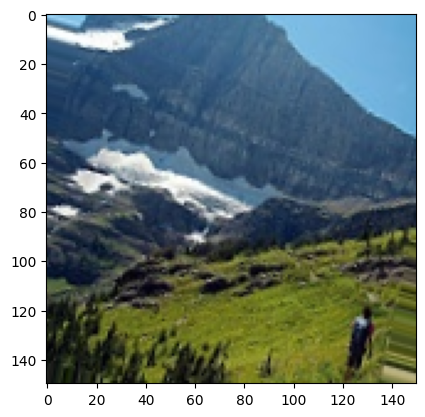

(64, 150, 150, 3)


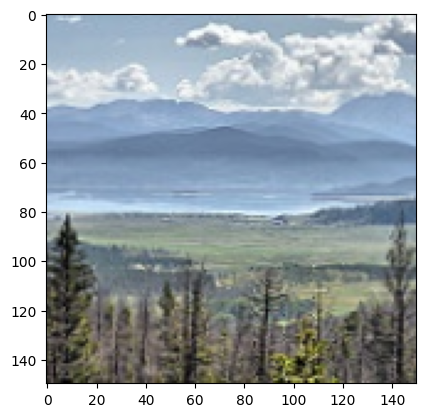

(64, 150, 150, 3)


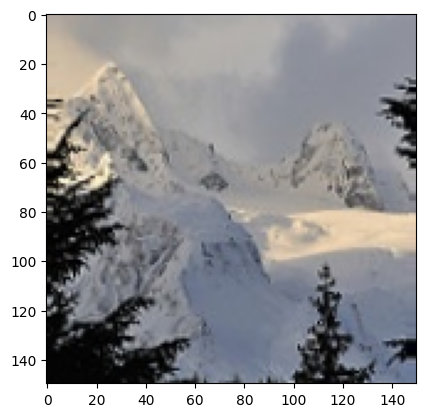

(64, 150, 150, 3)


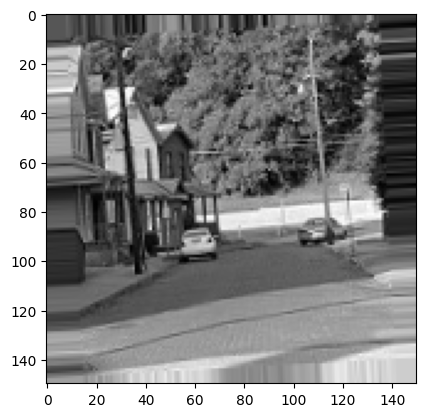

(64, 150, 150, 3)


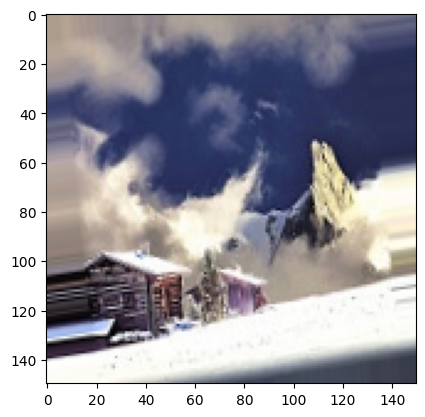

In [ ]:
for _ in range(5):
    img, label = next(train_generator)
    print(img.shape)
    plt.imshow(img[0])
    plt.show()

In [ ]:
for image_batch, label_batch in train_generator:
    break

print(f"Image batch shape: {image_batch.shape}")
print(f"Label batch shape: {label_batch.shape}")

IMG_SHAPE = (IMAGE_SIZE, IMAGE_SIZE, 3)

num_classes = 6

Image batch shape: (64, 150, 150, 3)
Label batch shape: (64, 6)


In [ ]:
model = Sequential()

#---------------------------------------
# Conv Block 1: 32 Filters, MaxPool.
#---------------------------------------
model.add(Conv2D(filters=32, kernel_size=3, padding='same', activation='relu', input_shape=IMG_SHAPE))
model.add(Conv2D(filters=32, kernel_size=3, padding='same', activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Dropout(0.1))
#---------------------------------------
# Conv Block 2: 64 Filters, MaxPool.
#---------------------------------------
model.add(Conv2D(filters=64, kernel_size=3, padding='same', activation='relu'))
model.add(Conv2D(filters=64, kernel_size=3, padding='same', activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))

# Flatten the convolutional features.
#---------------------------------------
model.add(Flatten())
model.add(Dense(512, activation='relu'))
model.add(Dense(num_classes, activation='softmax'))

model.compile(optimizer='rmsprop',
              loss='categorical_crossentropy',
              metrics=['accuracy'],
              )

model.summary()

Model: "sequential_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_36 (Conv2D)              │ (None, 150, 150, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_37 (Conv2D)              │ (None, 150, 150, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_18 (MaxPooling2D) │ (None, 75, 75, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 75, 75, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_38 (Conv2D)              │ (None, 75, 75, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_39 (Conv2D)              │ (None, 75, 75, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_19 (MaxPooling2D) │ (None, 37, 37, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_9 (Flatten)             │ (None, 87616)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_18 (Dense)                │ (None, 512)            │    44,859,904 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_19 (Dense)                │ (None, 6)              │         3,078 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 44,928,550 (171.39 MB)

 Trainable params: 44,928,550 (171.39 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
epochs = 20
callbacks = [
    EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True),
    ModelCheckpoint('best_model.keras', monitor='val_loss', save_best_only=True)
]
history = model.fit(train_generator,
                    epochs=epochs,
                    validation_data=val_generator,
                    callbacks=callbacks)
loss, acc = model.evaluate(val_generator, verbose=1)

Epoch 1/20
220/220 ━━━━━━━━━━━━━━━━━━━━ 102s 443ms/step - accuracy: 0.5181 - loss: 1.2502 - val_accuracy: 0.6473 - val_loss: 0.9364
Epoch 2/20
220/220 ━━━━━━━━━━━━━━━━━━━━ 98s 444ms/step - accuracy: 0.6660 - loss: 0.8771 - val_accuracy: 0.7410 - val_loss: 0.7064
Epoch 3/20
220/220 ━━━━━━━━━━━━━━━━━━━━ 97s 442ms/step - accuracy: 0.7182 - loss: 0.7511 - val_accuracy: 0.7557 - val_loss: 0.6703
Epoch 4/20
220/220 ━━━━━━━━━━━━━━━━━━━━ 96s 437ms/step - accuracy: 0.7482 - loss: 0.6838 - val_accuracy: 0.7840 - val_loss: 0.6060
Epoch 5/20
220/220 ━━━━━━━━━━━━━━━━━━━━ 97s 443ms/step - accuracy: 0.7804 - loss: 0.6045 - val_accuracy: 0.7850 - val_loss: 0.6006
Epoch 6/20
220/220 ━━━━━━━━━━━━━━━━━━━━ 95s 431ms/step - accuracy: 0.7943 - loss: 0.5650 - val_accuracy: 0.7857 - val_loss: 0.6229
Epoch 7/20
220/220 ━━━━━━━━━━━━━━━━━━━━ 97s 441ms/step - accuracy: 0.8072 - loss: 0.5257 - val_accuracy: 0.8110 - val_loss: 0.5559
Epoch 8/20
220/220 ━━━━━━━━━━━━━━━━━━━━ 95s 431ms/step - accuracy: 0.8193 - loss: 

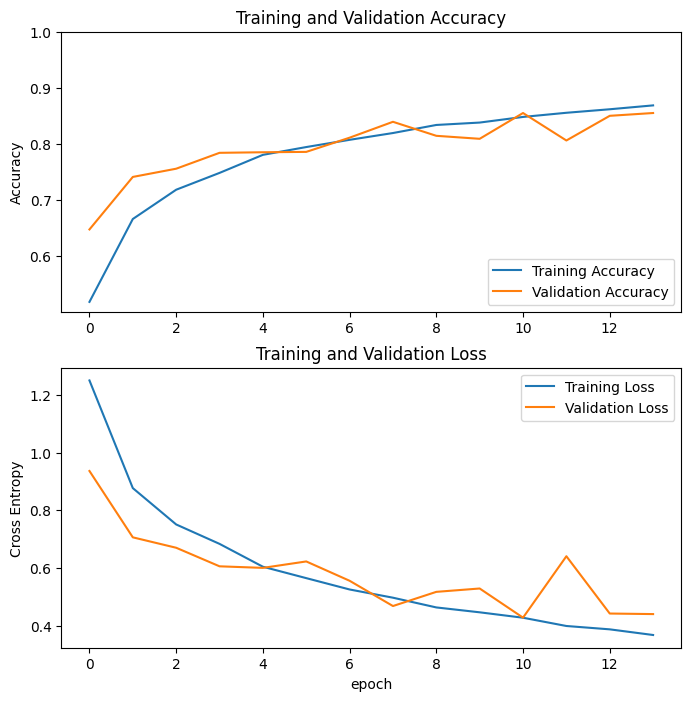

In [ ]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']

plt.figure(figsize=(8, 8))
plt.subplot(2, 1, 1)
plt.plot(acc, label='Training Accuracy')
plt.plot(val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.ylabel('Accuracy')
plt.ylim([min(plt.ylim()),1])
plt.title('Training and Validation Accuracy')

plt.subplot(2, 1, 2)
plt.plot(loss, label='Training Loss')
plt.plot(val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.ylabel('Cross Entropy')
plt.title('Training and Validation Loss')
plt.xlabel('epoch')
plt.show()